In [2]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Set project root directory
if Path.cwd().name == "notebooks":
    os.chdir("..")

PROJECT_ROOT = Path.cwd()

print("Project Root:", PROJECT_ROOT)
print("Python Environment Ready!")

Project Root: c:\Users\Diptesh\Desktop\axlero-churn-segmentation
Python Environment Ready!


In [3]:
DATA_PATH = PROJECT_ROOT / "data" / "raw"

print("Files available in raw folder:")

for file in DATA_PATH.rglob("*"):
    if file.is_file():
        print(file)

Files available in raw folder:
c:\Users\Diptesh\Desktop\axlero-churn-segmentation\data\raw\.gitkeep
c:\Users\Diptesh\Desktop\axlero-churn-segmentation\data\raw\online+retail+ii.zip
c:\Users\Diptesh\Desktop\axlero-churn-segmentation\data\raw\online+retail+ii\online_retail_II.xlsx


In [4]:

# Find Excel files inside the raw data folder

excel_files = list(DATA_PATH.rglob("*.xlsx"))

print("Excel files found:", len(excel_files))

for file in excel_files:
    print(file)


Excel files found: 1
c:\Users\Diptesh\Desktop\axlero-churn-segmentation\data\raw\online+retail+ii\online_retail_II.xlsx


In [5]:

# Select the Excel dataset

file_path = excel_files[0]

# Read Excel workbook information
excel_data = pd.ExcelFile(file_path)

print("Dataset:", file_path.name)
print("Available sheets:", excel_data.sheet_names)


Dataset: online_retail_II.xlsx
Available sheets: ['Year 2009-2010', 'Year 2010-2011']


In [9]:
from src.dataset import load_raw_data

df = load_raw_data()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (1067371, 8)


In [10]:
from pathlib import Path

file_path = Path("data/raw/online_retail_II.xlsx")

print("File exists:", file_path.exists())
print("Full path:", file_path.resolve())


File exists: True
Full path: C:\Users\Diptesh\Desktop\axlero-churn-segmentation\data\raw\online_retail_II.xlsx


In [11]:
df.head()

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [12]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   invoice       1067371 non-null  str           
 1   stock_code    1067371 non-null  str           
 2   description   1062989 non-null  object        
 3   quantity      1067371 non-null  int64         
 4   invoice_date  1067371 non-null  datetime64[us]
 5   price         1067371 non-null  float64       
 6   customer_id   824364 non-null   float64       
 7   country       1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(1), str(3)
memory usage: 65.1+ MB


In [13]:
df.describe()


,quantity,invoice_date,price,customer_id
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [14]:
print("Date Range:")
print("First Date:", df["invoice_date"].min())
print("Last Date:", df["invoice_date"].max())

print("\nUnique Customers:", df["customer_id"].nunique())
print("Unique Products:", df["stock_code"].nunique())
print("Unique Countries:", df["country"].nunique())

Date Range:
First Date: 2009-12-01 07:45:00
Last Date: 2011-12-09 12:50:00

Unique Customers: 5942
Unique Products: 5305
Unique Countries: 43


In [15]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
invoice              0
stock_code           0
description       4382
quantity             0
invoice_date         0
price                0
customer_id     243007
country              0
dtype: int64


In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary

,Missing Count,Missing Percentage
invoice,0,0.000000
stock_code,0,0.000000
description,4382,0.410541
quantity,0,0.000000
invoice_date,0,0.000000
price,0,0.000000
customer_id,243007,22.766873
country,0,0.000000


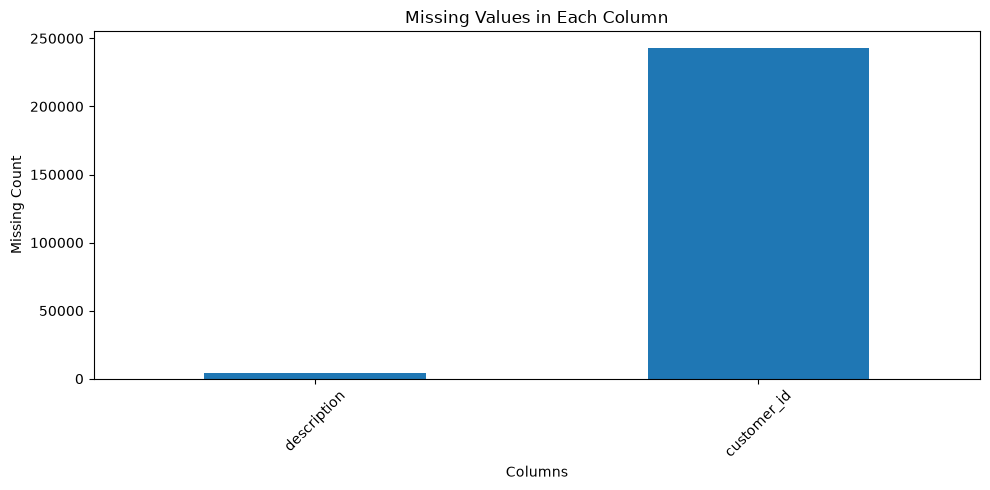

In [17]:
missing = df.isnull().sum()

missing = missing[missing > 0]

plt.figure(figsize=(10, 5))
missing.plot(kind="bar")

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Missing Count")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [18]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)
print("Duplicate Percentage:", (duplicate_count / len(df)) * 100)

Total Duplicate Rows: 34335
Duplicate Percentage: 3.2167821685243467


In [19]:
cancellations = df["invoice"].str.startswith("C", na=False).sum()

invalid_quantity = (df["quantity"] <= 0).sum()

invalid_price = (df["price"] <= 0).sum()

print("Cancellation Records:", cancellations)
print("Invalid Quantity Records:", invalid_quantity)
print("Invalid Price Records:", invalid_price)

Cancellation Records: 19494
Invalid Quantity Records: 22950
Invalid Price Records: 6207


In [20]:
non_product_codes = [
    "POST", "DOT", "M", "D", "C2",
    "BANK CHARGES", "AMAZONFEE",
    "ADJUST", "ADJUST2", "TEST001", "TEST002"
]

df["stock_code"] = df["stock_code"].astype(str)

non_product = df[df["stock_code"].isin(non_product_codes)]

print("Non-Product Records:", len(non_product))
print("\nStock Code Counts:")
print(non_product["stock_code"].value_counts())

Non-Product Records: 5680

Stock Code Counts:
stock_code
POST            2122
DOT             1446
M               1421
C2               282
D                177
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
TEST001           15
ADJUST2            3
TEST002            2
Name: count, dtype: int64


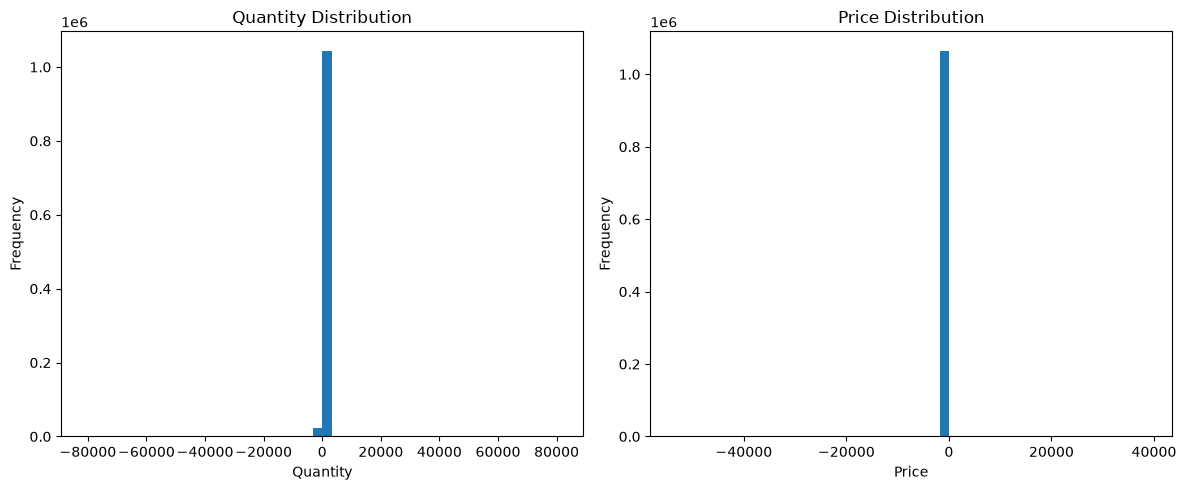

In [21]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df["quantity"], bins=50)
plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(df["price"], bins=50)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

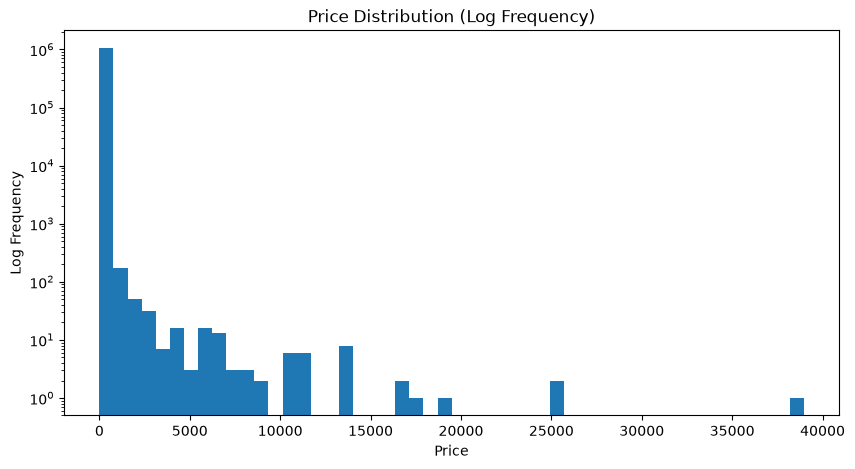

In [22]:
plt.figure(figsize=(10, 5))

positive_prices = df.loc[df["price"] > 0, "price"]

plt.hist(positive_prices, bins=50, log=True)

plt.title("Price Distribution (Log Frequency)")
plt.xlabel("Price")
plt.ylabel("Log Frequency")

plt.show()

In [23]:
print("Highest 10 Quantities:")
print(df.nlargest(10, "quantity")[["invoice", "stock_code", "quantity", "price"]])

print("\nHighest 10 Prices:")
print(df.nlargest(10, "price")[["invoice", "stock_code", "quantity", "price"]])

Highest 10 Quantities:
        invoice stock_code  quantity  price
1065882  581483      23843     80995   2.08
587080   541431      23166     74215   1.04
90857    497946      37410     19152   0.10
127166   501534      21099     12960   0.10
127168   501534      21091     12960   0.10
127169   501534      21085     12744   0.10
1027583  578841      84826     12540   0.00
127167   501534      21092     12480   0.10
192197   507637      84016     10200   0.00
135027   502269      21984     10000   0.25

Highest 10 Prices:
         invoice    stock_code  quantity     price
748142   C556445             M        -1  38970.00
241824   C512770             M        -1  25111.09
241827    512771             M         1  25111.09
320581   C520667  BANK CHARGES        -1  18910.69
1050063  C580605     AMAZONFEE        -1  17836.46
569163   C540117     AMAZONFEE        -1  16888.02
569164   C540118     AMAZONFEE        -1  16453.71
517953   C537630     AMAZONFEE        -1  13541.33
517955    5376

In [24]:
from pathlib import Path

figures_path = Path("reports/figures")
figures_path.mkdir(parents=True, exist_ok=True)

print("Figures folder ready:", figures_path.resolve())

Figures folder ready: C:\Users\Diptesh\Desktop\axlero-churn-segmentation\reports\figures


In [25]:
plt.savefig("reports/figures/eda_quantity_price.png", bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [26]:
clean_df = pd.read_csv(
    "data/interim/online_retail_clean.csv",
    parse_dates=["invoice_date"]
)

print("Cleaned dataset loaded!")
print("Shape:", clean_df.shape)

Cleaned dataset loaded!
Shape: (1033036, 14)


In [27]:
print("Customer ID available:")
print(clean_df["has_customer_id"].value_counts())

print("\nCancellations:")
print(clean_df["is_cancellation"].value_counts())

print("\nNon-product records:")
print(clean_df["is_non_product"].value_counts())

print("\nValid sales:")
print(clean_df["is_valid_sale"].value_counts())

Customer ID available:
has_customer_id
True     797885
False    235151
Name: count, dtype: int64

Cancellations:
is_cancellation
False    1013932
True       19104
Name: count, dtype: int64

Non-product records:
is_non_product
False    1027465
True        5571
Name: count, dtype: int64

Valid sales:
is_valid_sale
True     1003443
False      29593
Name: count, dtype: int64


In [28]:
print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

removed_percentage = (
    (len(df) - len(clean_df)) / len(df)
) * 100

print("Removal percentage:", round(removed_percentage, 2), "%")

Original rows: 1067371
Cleaned rows: 1033036
Rows removed: 34335
Removal percentage: 3.22 %


In [29]:
valid_sales = clean_df[clean_df["is_valid_sale"]]

print("Valid sales records:", len(valid_sales))
print("Total revenue:", round(valid_sales["line_total"].sum(), 2))
print("Unique customers:", valid_sales["customer_id"].nunique())

Valid sales records: 1003443
Total revenue: 19006243.4
Unique customers: 5852


In [30]:
sales_df = clean_df[
    clean_df["is_valid_sale"]
].copy()

print("Sales records:", len(sales_df))
print("Total revenue:", round(sales_df["line_total"].sum(), 2))

Sales records: 1003443
Total revenue: 19006243.4


In [31]:
monthly_revenue = (
    sales_df.groupby("year_month")["line_total"]
    .sum()
    .sort_index()
)

print(monthly_revenue)

year_month
2009-12    7.865398e+05
2010-01    6.025765e+05
2010-02    5.207174e+05
2010-03    7.404197e+05
2010-04    6.442063e+05
2010-05    6.275387e+05
2010-06    6.799938e+05
2010-07    6.306641e+05
2010-08    6.612666e+05
2010-09    8.411285e+05
2010-10    1.076583e+06
2010-11    1.390568e+06
2010-12    7.620227e+05
2011-01    5.702909e+05
2011-02    5.003127e+05
2011-03    6.831064e+05
2011-04    4.972619e+05
2011-05    7.291188e+05
2011-06    7.053862e+05
2011-07    6.856579e+05
2011-08    7.153395e+05
2011-09    1.005692e+06
2011-10    1.084164e+06
2011-11    1.432028e+06
2011-12    4.336607e+05
Name: line_total, dtype: float64


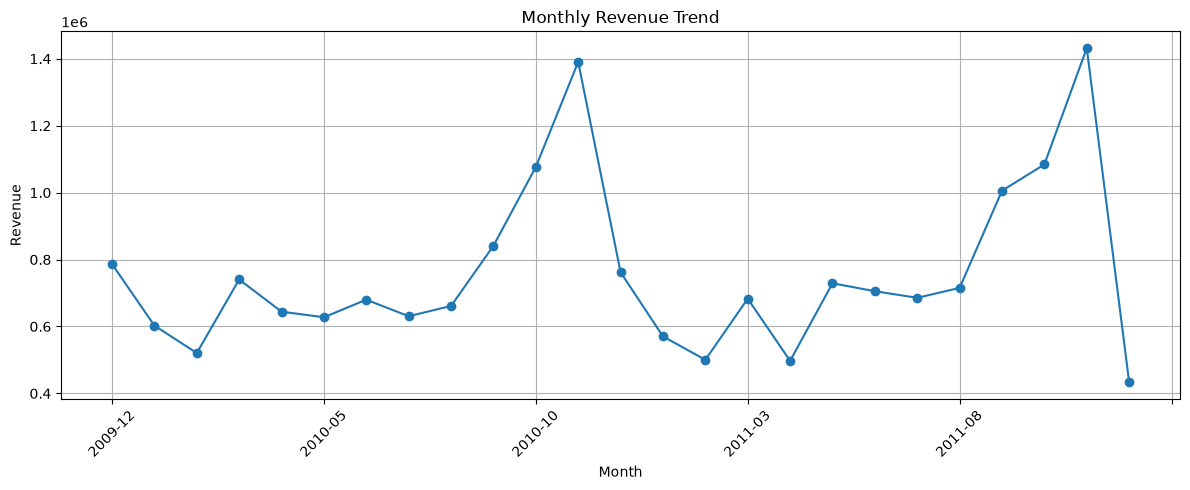

In [32]:
plt.figure(figsize=(12, 5))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.savefig(
    "reports/figures/eda_monthly_revenue.png",
    bbox_inches="tight"
)
plt.show()

In [33]:
country_revenue = (
    sales_df.groupby("country")["line_total"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_revenue)

country
United Kingdom    1.622333e+07
EIRE              6.219308e+05
Netherlands       5.398968e+05
Germany           3.831642e+05
France            3.015138e+05
Australia         1.660960e+05
Spain             9.710691e+04
Switzerland       9.402459e+04
Sweden            8.439554e+04
Belgium           5.699317e+04
Name: line_total, dtype: float64


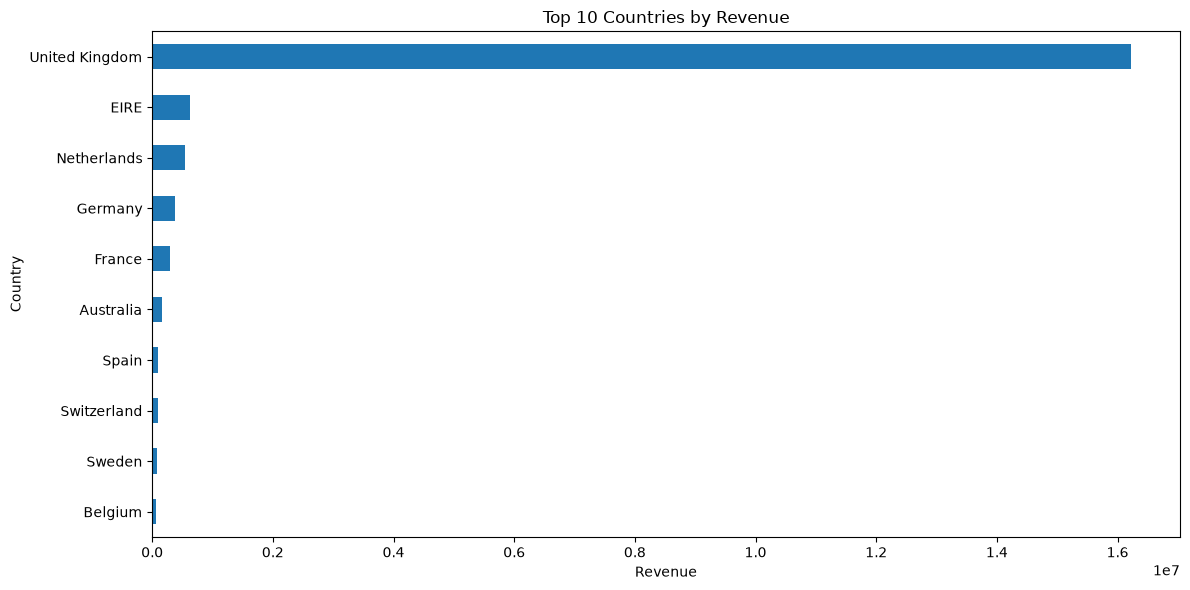

In [34]:
plt.figure(figsize=(12, 6))

country_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.savefig(
    "reports/figures/eda_top_countries.png",
    bbox_inches="tight"
)
plt.show()

In [35]:
sales_df["weekday"] = sales_df["invoice_date"].dt.day_name()

weekday_revenue = (
    sales_df.groupby("weekday")["line_total"]
    .sum()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_revenue = weekday_revenue.reindex(weekday_order)

print(weekday_revenue)

weekday
Monday       3.323948e+06
Tuesday      3.707319e+06
Wednesday    3.337906e+06
Thursday     3.919546e+06
Friday       2.927806e+06
Saturday     9.803050e+03
Sunday       1.779916e+06
Name: line_total, dtype: float64


In [36]:
top_products = (
    sales_df.groupby("description")["line_total"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

description
REGENCY CAKESTAND 3 TIER              330590.32
WHITE HANGING HEART T-LIGHT HOLDER    247850.16
PARTY BUNTING                         148318.28
JUMBO BAG RED RETROSPOT               144660.99
ASSORTED COLOUR BIRD ORNAMENT         117978.49
PAPER CHAIN KIT 50'S CHRISTMAS        110859.64
CHILLI LIGHTS                          80540.88
JUMBO BAG STRAWBERRY                   68176.89
BLACK RECORD COVER FRAME               63643.45
JUMBO STORAGE BAG SUKI                 61537.55
Name: line_total, dtype: float64


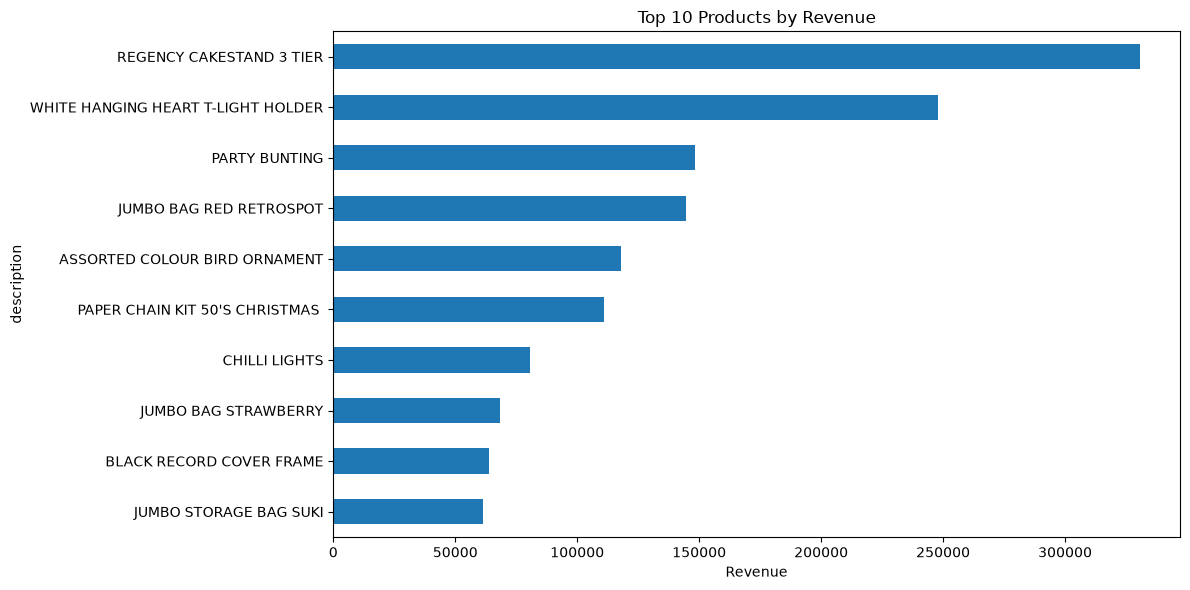

In [37]:
plt.figure(figsize=(12, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.savefig("reports/figures/eda_top_products.png")
plt.show()

In [38]:
customer_orders = (
    sales_df.groupby("customer_id")["invoice"]
    .nunique()
)

print(customer_orders.describe())

count    5852.000000
mean        6.253247
std        12.749286
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       373.000000
Name: invoice, dtype: float64


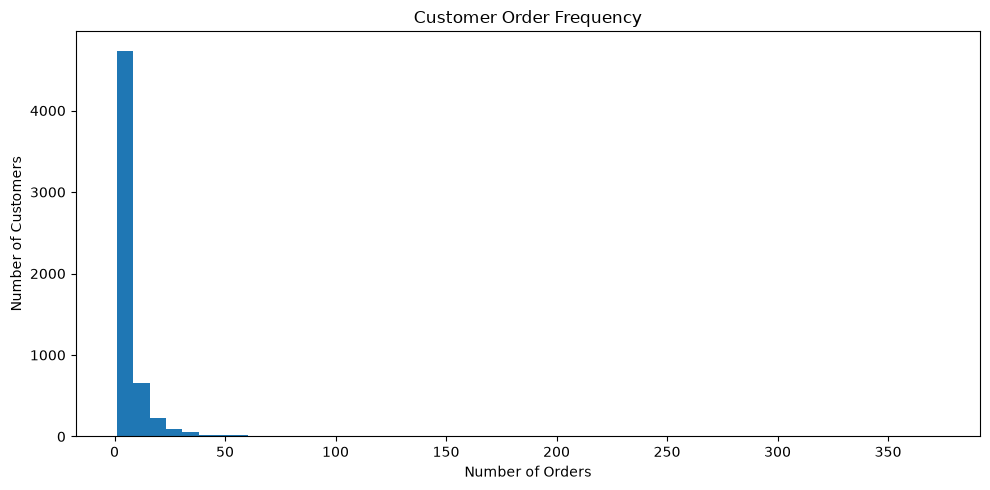

In [39]:
plt.figure(figsize=(10, 5))
plt.hist(customer_orders, bins=50)

plt.title("Customer Order Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("reports/figures/eda_customer_orders.png")
plt.show()

In [40]:
top_customers = (
    sales_df[sales_df["customer_id"].notna()]
    .groupby("customer_id")["line_total"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers)

customer_id
18102.0    566178.46000
14646.0    516874.87008
14156.0    301612.36000
14911.0    272226.95000
17450.0    204736.37000
13694.0    193823.65000
17511.0    172103.11000
16684.0    144809.33000
12415.0    142329.37000
15061.0    125336.61000
Name: line_total, dtype: float64


In [41]:
print("========== AX LERO EDA SUMMARY ==========")

print("Total records:", len(clean_df))
print("Valid sales:", len(sales_df))
print("Unique customers:", sales_df["customer_id"].nunique())
print("Unique products:", sales_df["stock_code"].nunique())
print("Total revenue:", round(sales_df["line_total"].sum(), 2))

print("\nTop country:")
print(country_revenue.idxmax())

print("\nTop product:")
print(top_products.index[0])

print("\nHighest revenue month:")
print(monthly_revenue.idxmax())

========== AX LERO EDA SUMMARY ==========
Total records: 1033036
Valid sales: 1003443
Unique customers: 5852
Unique products: 4906
Total revenue: 19006243.4

Top country:
United Kingdom

Top product:
REGENCY CAKESTAND 3 TIER

Highest revenue month:
2011-11
